# Phase 2 — Conservative IPA transcript policy

This notebook uses the **5,086 first-pass Narration candidates** from Phase 1. It creates a derived evaluation/training label with Unicode NFD, outer whitespace trimming, and repeated ordinary-space collapse. The original `transcript_raw` stays intact.

No pronunciation, dental, tone, length, aspiration, or punctuation symbols are rewritten. This notebook does not make speaker splits or train a model. Run cells in order; do not publish local manifests containing transcripts or speaker metadata.

In [1]:
from pathlib import Path
from datetime import datetime
from collections import Counter
import hashlib
import json
import re
import unicodedata

import pandas as pd
from IPython.display import display

current = Path.cwd().resolve()
project = next(
    (p for p in (current, *current.parents)
     if (p / "manifests" / "master_A_v1_1.parquet").is_file()),
    None,
)
if project is None:
    raise FileNotFoundError("Open this notebook from inside the BTP project.")

phase1_dir = project / "outputs" / "phase1_20261031_202929"
source_path = phase1_dir / "phase1_candidates.parquet"
if not source_path.is_file():
    raise FileNotFoundError(source_path)

def file_sha256(path):
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

source_hash = file_sha256(source_path)
data = pd.read_parquet(source_path)
required = {"sample_id", "transcript_raw", "phase1_candidate", "duration_decoded"}
missing = required - set(data.columns)
if missing:
    raise ValueError(f"Missing required columns: {sorted(missing)}")
if data["sample_id"].isna().any() or data["sample_id"].duplicated().any():
    raise ValueError("Candidate sample IDs must be present and unique.")
if not data["phase1_candidate"].fillna(False).all():
    raise ValueError("Source contains rows not marked as Phase 1 candidates.")
if data["transcript_raw"].isna().any():
    raise ValueError("A candidate has a null raw transcript; investigate Phase 1.")

print("Source:", source_path.relative_to(project))
print("Candidate rows:", len(data))
print("Source SHA-256:", source_hash)

Source: outputs/phase1_20261031_202929/phase1_candidates.parquet
Candidate rows: 5086
Source SHA-256: 3ff48a06b992199d076f36632dd3e105d4f4006c9c92555d5c02b1eaf17f0a9c


## 1. Define and apply the approved mechanical policy

NFD represents combining marks consistently. Only leading/trailing whitespace and runs of ordinary U+0020 spaces are adjusted. A tab inside a transcript, punctuation mark, or IPA symbol remains visible for review.

In [2]:
def normalize_minimal(text):
    if not isinstance(text, str):
        raise TypeError(f"Expected transcript string, received {type(text).__name__}")
    return re.sub(r" +", " ", unicodedata.normalize("NFD", text.strip()))

raw = data["transcript_raw"].astype(str)
data["transcript_phase2"] = raw.map(normalize_minimal)
data["changed_nfd"] = raw.map(
    lambda s: unicodedata.normalize("NFD", s) != s
)
data["changed_outer_whitespace"] = raw.map(lambda s: s.strip() != s)
data["had_repeated_ordinary_spaces"] = raw.str.contains(r" {2,}", regex=True)
data["changed_any"] = data["transcript_phase2"].ne(raw)

if data["transcript_phase2"].eq("").any():
    raise ValueError("Normalization created an empty candidate label.")
if not data["transcript_phase2"].map(
    lambda s: unicodedata.normalize("NFD", s) == s
).all():
    raise ValueError("A normalized label is not NFD.")
if not data["transcript_phase2"].map(normalize_minimal).equals(
    data["transcript_phase2"]
):
    raise ValueError("Normalization is not idempotent.")

print("Rows changed by final policy:", int(data["changed_any"].sum()))
print("Rows changed by NFD alone:", int(data["changed_nfd"].sum()))
print("Rows with outer whitespace:", int(data["changed_outer_whitespace"].sum()))
print("Rows with repeated ordinary spaces in raw text:",
      int(data["had_repeated_ordinary_spaces"].sum()))
print("All normalized labels nonempty and idempotent.")

Rows changed by final policy: 497
Rows changed by NFD alone: 0
Rows with outer whitespace: 0
Rows with repeated ordinary spaces in raw text: 497
All normalized labels nonempty and idempotent.


## 2. Quantify label changes and inspect Unicode

Counts for individual rules can overlap. The combined changed-row count counts each row once. The inventory counts Unicode code points, including combining marks; it is not a phoneme inventory or a linguistic judgment.

In [3]:
data["raw_codepoints"] = raw.str.len()
data["phase2_codepoints"] = data["transcript_phase2"].str.len()
data["codepoint_delta"] = data["phase2_codepoints"] - data["raw_codepoints"]

raw_counter = Counter("".join(raw))
normalized_counter = Counter("".join(data["transcript_phase2"]))
inventory = pd.DataFrame([
    {
        "codepoint": f"U+{ord(char):04X}",
        "symbol": char,
        "unicode_name": unicodedata.name(char, "UNASSIGNED"),
        "category": unicodedata.category(char),
        "combining_class": unicodedata.combining(char),
        "raw_count": count,
        "normalized_count": normalized_counter.get(char, 0),
    }
    for char, count in raw_counter.items()
]).sort_values(["raw_count", "codepoint"], ascending=[False, True]).reset_index(drop=True)

print("Distinct raw code points:", len(raw_counter))
print("Distinct normalized code points:", len(normalized_counter))
print("Total raw code points:", int(data["raw_codepoints"].sum()))
print("Total normalized code points:", int(data["phase2_codepoints"].sum()))
print("Rows shortened:", int(data["codepoint_delta"].lt(0).sum()))
print("Rows lengthened:", int(data["codepoint_delta"].gt(0).sum()))
print("Combining marks in normalized labels:")
display(inventory.loc[inventory["category"].str.startswith("M"),
                      ["codepoint", "unicode_name", "normalized_count"]])
print("Most frequent non-space characters:")
display(inventory.loc[inventory["symbol"].ne(" "),
                      ["codepoint", "symbol", "unicode_name", "raw_count"]].head(20))

Distinct raw code points: 102
Distinct normalized code points: 102
Total raw code points: 522368
Total normalized code points: 521747
Rows shortened: 497
Rows lengthened: 0
Combining marks in normalized labels:


,codepoint,unicode_name,normalized_count
18,U+032A,COMBINING BRIDGE BELOW,9747
52,U+0303,COMBINING TILDE,24
56,U+031F,COMBINING PLUS SIGN BELOW,16
58,U+0306,COMBINING BREVE,14
70,U+033A,COMBINING INVERTED BRIDGE BELOW,3
76,U+0301,COMBINING ACUTE ACCENT,2
77,U+0308,COMBINING DIAERESIS,2
100,U+0325,COMBINING RING BELOW,1


Most frequent non-space characters:


,codepoint,symbol,unicode_name,raw_count
1,U+0061,a,LATIN SMALL LETTER A,49444
2,U+006F,o,LATIN SMALL LETTER O,33077
3,U+006D,m,LATIN SMALL LETTER M,29454
4,U+0065,e,LATIN SMALL LETTER E,28830
5,U+006C,l,LATIN SMALL LETTER L,28767
6,U+0075,u,LATIN SMALL LETTER U,23416
7,U+0069,i,LATIN SMALL LETTER I,23357
8,U+006E,n,LATIN SMALL LETTER N,22261
9,U+0259,ə,LATIN SMALL LETTER SCHWA,21813
10,U+0064,d,LATIN SMALL LETTER D,16869


## 3. Inspect review signals without changing labels

The following table counts characters often discussed in the recovered notebooks. Their presence is **not** evidence of a transcription error. Leave ambiguous cases for a separate human review decision.

In [4]:
watch = ["g", "ɡ", ":", ";", "[", "]", "ː", "̪", "?", "ʔ", "́"]
watch_table = pd.DataFrame([
    {
        "symbol": char,
        "codepoint": f"U+{ord(char):04X}",
        "name": unicodedata.name(char, "UNASSIGNED"),
        "raw_count": raw_counter.get(char, 0),
        "phase2_count": normalized_counter.get(char, 0),
        "rows_containing": int(data["transcript_phase2"].str.contains(
            re.escape(char), regex=True
        ).sum()),
    }
    for char in watch
])
display(watch_table)
print("No substitutions of these characters were performed.")

,symbol,codepoint,name,raw_count,phase2_count,rows_containing
0,g,U+0067,LATIN SMALL LETTER G,6184,6184,2036
1,ɡ,U+0261,LATIN SMALL LETTER SCRIPT G,6239,6239,1633
2,:,U+003A,COLON,5,5,3
3,;,U+003B,SEMICOLON,20,20,20
4,[,U+005B,LEFT SQUARE BRACKET,21,21,19
5,],U+005D,RIGHT SQUARE BRACKET,0,0,0
6,ː,U+02D0,MODIFIER LETTER TRIANGULAR COLON,4532,4532,1397
7,̪,U+032A,COMBINING BRIDGE BELOW,9747,9747,2233
8,?,U+003F,QUESTION MARK,13,13,13
9,ʔ,U+0294,LATIN LETTER GLOTTAL STOP,469,469,300


No substitutions of these characters were performed.


## 4. Visual checks for thesis analysis

These plots show what the mechanical policy changes and the distribution of label lengths. They are descriptive figures, not model results. Install Matplotlib in the selected environment if the next cell says it is unavailable, then rerun the cell.

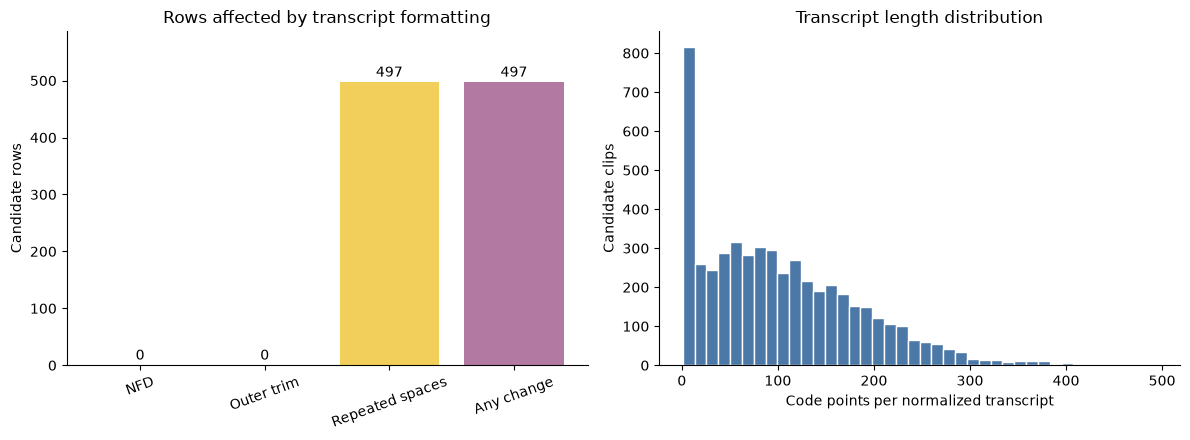

In [5]:
try:
    import matplotlib.pyplot as plt
except ImportError:
    print("Matplotlib is unavailable. In a separate notebook cell run "
          "%pip install matplotlib, then rerun this cell.")
else:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    counts = [
        int(data["changed_nfd"].sum()),
        int(data["changed_outer_whitespace"].sum()),
        int(data["had_repeated_ordinary_spaces"].sum()),
        int(data["changed_any"].sum()),
    ]
    labels = ["NFD", "Outer trim", "Repeated spaces", "Any change"]
    axes[0].bar(labels, counts, color=["#4c78a8", "#72b7b2", "#f2cf5b", "#b279a2"])
    axes[0].set_ylabel("Candidate rows")
    axes[0].set_title("Rows affected by transcript formatting")
    axes[0].tick_params(axis="x", rotation=20)
    for i, count in enumerate(counts):
        axes[0].text(i, count + max(counts + [1]) * 0.02,
                     f"{count:,}", ha="center")
    axes[0].set_ylim(0, max(counts + [1]) * 1.18)

    axes[1].hist(data["phase2_codepoints"], bins=40,
                 color="#4c78a8", edgecolor="white")
    axes[1].set_xlabel("Code points per normalized transcript")
    axes[1].set_ylabel("Candidate clips")
    axes[1].set_title("Transcript length distribution")
    for ax in axes:
        ax.spines[["top", "right"]].set_visible(False)
    fig.tight_layout()
    plt.show()

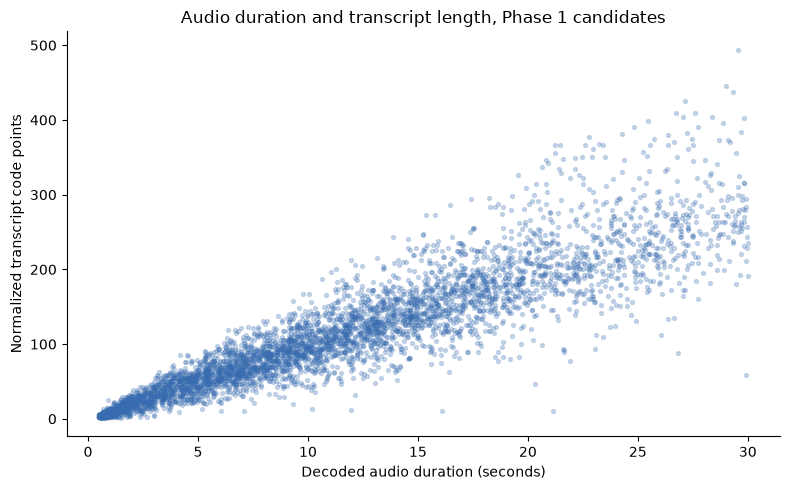

Plot uses 5086 first-pass candidates.


In [6]:
try:
    import matplotlib.pyplot as plt
except ImportError:
    print("Install Matplotlib as described above to draw this plot.")
else:
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.scatter(data["duration_decoded"], data["phase2_codepoints"],
               s=8, alpha=0.25, color="#386cb0")
    ax.set_xlabel("Decoded audio duration (seconds)")
    ax.set_ylabel("Normalized transcript code points")
    ax.set_title("Audio duration and transcript length, Phase 1 candidates")
    ax.spines[["top", "right"]].set_visible(False)
    fig.tight_layout()
    plt.show()

    # Long transcripts at short durations are review leads, not automatic exclusions.
    print("Plot uses", len(data), "first-pass candidates.")

## 5. Save local, versioned outputs

The saved manifest keeps all Phase 1 columns, the raw transcript, the derived transcript, and change flags. The summary records source hashes and counts. No model tokenizer is loaded here; tokenizer round-trip and target-length checks belong to the model smoke-test phase.

In [7]:
run_id = datetime.now().astimezone().strftime("%Y%m%d_%H%M%S")
output_dir = project / "outputs" / f"phase2_{run_id}"
output_dir.mkdir(parents=True, exist_ok=False)
manifest_path = output_dir / "phase2_candidates.parquet"
inventory_path = output_dir / "unicode_inventory.csv"
watch_path = output_dir / "symbol_watch.csv"
summary_path = output_dir / "summary.json"

data.to_parquet(manifest_path, index=False)
inventory.to_csv(inventory_path, index=False)
watch_table.to_csv(watch_path, index=False)

summary = {
    "phase": 2,
    "status": "mechanical_policy_completed_linguistic_review_pending",
    "created_at": datetime.now().astimezone().isoformat(timespec="seconds"),
    "source": str(source_path.relative_to(project)),
    "source_sha256": source_hash,
    "candidate_rows": int(len(data)),
    "candidate_decoded_hours": float(data["duration_decoded"].sum() / 3600),
    "policy": "NFD, strip outer whitespace, collapse runs of ordinary U+0020 spaces",
    "changed_rows": int(data["changed_any"].sum()),
    "nfd_changed_rows": int(data["changed_nfd"].sum()),
    "outer_whitespace_rows": int(data["changed_outer_whitespace"].sum()),
    "repeated_ordinary_space_rows": int(data["had_repeated_ordinary_spaces"].sum()),
    "raw_codepoint_types": len(raw_counter),
    "normalized_codepoint_types": len(normalized_counter),
    "tokenizer_roundtrip": None,
    "speaker_split": None,
}
summary_path.write_text(json.dumps(summary, ensure_ascii=False, indent=2) + "\n",
                        encoding="utf-8")
if file_sha256(source_path) != source_hash:
    raise RuntimeError("Phase 1 source changed during this run.")
print("Saved:", output_dir)
print("Manifest SHA-256:", file_sha256(manifest_path))
print("Source hash unchanged. No linguistic substitutions or splits performed.")

Saved: /Users/kanchanpotdar/Downloads/BTP/outputs/phase2_20261031_205009
Manifest SHA-256: cdffb2605f5e0de2168fbc093dc4c7937b808437aa20b0fb5705b596bd7b1681
Source hash unchanged. No linguistic substitutions or splits performed.


## Phase 2 conclusion

**Status:** Conservative mechanical transcript policy completed. Linguistic review and model tokenizer checks remain open.

- **Input:** The 5,086 Phase 1 Narration candidates, comprising approximately 14.826 decoded hours.
- **Policy:** Preserve `transcript_raw`. Create `transcript_phase2` using Unicode NFD, trimming of outer whitespace, and collapse of repeated ordinary U+0020 spaces. No IPA symbols, diacritics, punctuation, word boundaries, or pronunciation variants were rewritten.
- **Observed changes:** 497 of 5,086 labels changed (9.77%). All changes were repeated ordinary spaces. NFD changed zero rows; outer trimming changed zero rows. Total transcript code points decreased from 522,368 to 521,747, a difference of 621 spaces. The number of distinct code points remained 102 in both views. These counts describe the Phase 1 candidate subset, not all 6,718 master rows.
- **Checks:** Derived labels remained nonempty and in NFD. Reapplying the policy produced no further changes. The Phase 1 source hash was unchanged.
- **Symbols retained:** Dental, nasalization, length, aspiration, acute accent, and other combining marks remain in the labels. Rare occurrence alone is not evidence of an error or of phonetic equivalence.
- **Targeted review:** Colon `:` appears 5 times in 3 rows; semicolon `;` 20 times in 20 rows; left square bracket `[` 21 times in 19 rows. Their union is 41 distinct candidate clips (approximately 0.195 hours). Review these rows individually before using them as primary held-out references; do not apply global deletion or substitution. The combining acute accent occurs twice in one row and should be preserved while its meaning is reviewed.
- **Model checks pending:** Verify that the pinned IPA-Whisper processor can encode and decode the complete target inventory, including combining marks, and that no target is truncated. Apply the declared evaluation normalization consistently to references and predictions.
- **Output:** `outputs/phase2_20261031_205009/` contains the derived candidate manifest, Unicode inventory, symbol watch list, and summary. The source manifest was unchanged.
- **Next:** Complete the targeted symbol review and Phase 2.5 speaker/group review, then create and audit speaker/session-disjoint splits in Phase 3. No final split or model result has been produced.